# Cleaning & Preparing Raw Data for Machine Learning
### A hands-on lab on Indian road-accident data (2005 – 2023)

**What you will be able to do by the end of this notebook**

| # | Skill | Why it matters for ML |
|---|-------|-----------------------|
| 1 | Import a CSV and profile it (`shape`, `info`, `dtypes`, `describe`) | You cannot fix what you cannot see. Garbage dtypes silently break every model. |
| 2 | Handle missing values (drop / mean / median / mode / group-wise / KNN imputation) | Most algorithms refuse `NaN` or quietly learn the wrong thing from it. |
| 3 | Encode categorical features (one-hot, ordinal, label, target) | Models only multiply numbers — text must become numbers *without* inventing an order that isn't there. |
| 4 | Normalise / standardise numerical features | A feature measured in lakhs must not bully a feature measured in tens. |
| 5 | Visualise outliers with boxplots and remove them | One bad row can drag a regression line across the whole state. |

**The dataset** — `data/india_road_accidents_raw.csv`, one row per *(state × year × road type × vehicle type)* accident cluster.
The yearly national totals are the real MoRTH / NCRB published figures (e.g. **4,80,583 accidents and 1,72,890 deaths in 2023**).
The row-level detail is a realistic reconstruction, and the file has been **deliberately corrupted** the way real downloads are:
messy category spellings, `NA` / `N/A` / `-` / `null` / `Unknown`, numbers saved as text (`"1,234"`), sentinel codes like `999`,
duplicated rows, and a handful of genuinely impossible values. Your job is to clean it.

**The golden rule of this whole notebook**

> Learn every cleaning statistic (mean, median, scaler, encoder, outlier bound) from the **training set only** —
> fit on train, `transform` on test. Otherwise information leaks from test into train and your offline score becomes a lie.

Let's set up the environment first.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

SEVERITY_ORDER = {"Minor": 0, "Serious": 1, "Fatal": 2}

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (11, 4.5)
RANDOM_STATE = 42
print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 2.2.3 | numpy 2.3.5


---
## Step 1 — Import the dataset and explore basic info

Before touching a single value, answer four questions:

1. **How big is it?** → `shape`
2. **What type is each column?** → `dtypes` / `info()`. A number showing up as `object` is a red flag.
3. **How dirty is it?** → `isna().sum()`, `nunique()`, `value_counts()`
4. **Do the numbers make physical sense?** → `describe()`

`dtype` is the single most informative thing about a column. `accidents` being `object` instead of `int64` means
there is text hiding inside it, and *every* calculation you run on it will fail or silently mislead.

In [2]:
df = pd.read_csv("data/india_road_accidents_raw.csv")

print("Rows, columns:", df.shape)
df.head()

Rows, columns: (10465, 14)


,state,year,road_type,vehicle_type,weather,accident_cause,severity,accidents,deaths,injuries,vehicles_involved,speed_limit_kmph,driver_age_median,alcohol_involved
0,Tamil Nadu,2008,Other Roads,Two-wheeler,Clear,Overspeeding,Minor,19543,3737,19279,6.0,50,29.747119989616916,No
1,Karnataka,2011,National Highway,Car / Taxi / Van,Clear,Overspeeding,Serious,2939,926,5429,2.0,90,47.13792554471542,No
2,Tamil Nadu,2018,State Highway,Two-wheeler,rainy,Overspeeding,Serious,4005,971,3918,3.0,80,29.762948301750814,NaN
3,Himachal Pradesh,2009,Other Roads,Two-wheeler,Clear,Other,Minor,730,131,607,4.0,70,21.172459481520875,No
4,Mizoram,2021,National Highway,Bus,NaN,Overspeeding,Serious,13,5,17,5.0,90,27.603387947336795,No


In [3]:
# info() = dtype + non-null count per column, in one shot
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10465 entries, 0 to 10464
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   state              10465 non-null  object 
 1   year               10465 non-null  int64  
 2   road_type          10465 non-null  object 
 3   vehicle_type       10465 non-null  object 
 4   weather            9831 non-null   object 
 5   accident_cause     9658 non-null   object 
 6   severity           10465 non-null  object 
 7   accidents          10465 non-null  object 
 8   deaths             10465 non-null  object 
 9   injuries           10110 non-null  object 
 10  vehicles_involved  10049 non-null  float64
 11  speed_limit_kmph   9935 non-null   object 
 12  driver_age_median  9792 non-null   object 
 13  alcohol_involved   9988 non-null   object 
dtypes: float64(1), int64(1), object(12)
memory usage: 1.1+ MB


In [4]:
# Which columns are numeric vs text? And how many distinct values does each hold?
profile = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_null": df.notna().sum(),
    "missing_%": (df.isna().mean() * 100).round(1),
    "n_unique": df.nunique(),
    "example": [df[c].dropna().iloc[0] for c in df.columns],
})
profile

,dtype,non_null,missing_%,n_unique,example
state,object,10465,0.0,60,Tamil Nadu
year,int64,10465,0.0,19,2008
road_type,object,10465,0.0,6,Other Roads
vehicle_type,object,10465,0.0,8,Two-wheeler
weather,object,9831,6.1,10,Clear
accident_cause,object,9658,7.7,8,Overspeeding
severity,object,10465,0.0,3,Minor
accidents,object,10465,0.0,2735,19543
deaths,object,10465,0.0,1346,3737
injuries,object,10110,3.4,2638,19279


Look at that table: `accidents`, `deaths`, `injuries`, `vehicles_involved`, `speed_limit_kmph` and `driver_age_median`
are all `object`. They are numbers trapped in text. Let's prove it:

In [5]:
# The tell-tale sign: numbers stored as text sort alphabetically
print("dtype:", df["deaths"].dtype)
print(df["deaths"].astype(str).str.sort_values if False else "")
print(sorted(df["deaths"].astype(str).unique(), reverse=True)[:6])

# ...and string methods work on them, which is a dead giveaway
print("\ncontains commas:", df["deaths"].astype(str).str.contains(",").sum(), "rows")

dtype: object

['998', '996', '995', '993', '992', '990']

contains commas: 49 rows


In [6]:
# The text columns hide junk spellings of the same category
for col in ["state", "road_type", "vehicle_type", "weather", "alcohol_involved"]:
    vals = sorted(df[col].dropna().astype(str).unique())
    print(f"{col:18s} ({len(vals):2d} variants): {vals}")

state              (60 variants): ['ANDHRA PRADESH', 'ARUNACHAL PRADESH', 'ASSAM', 'Andhra Pradesh', 'Arunachal Pradesh', 'Assam', 'BIHAR', 'Bihar', 'CHHATTISGARH', 'Chhattisgarh', 'DELHI', 'Delhi', 'GOA', 'GUJARAT', 'Goa', 'Gujarat', 'HARYANA', 'HIMACHAL PRADESH', 'Haryana', 'Himachal Pradesh', 'JAMMU & KASHMIR', 'JHARKHAND', 'Jammu & Kashmir', 'Jharkhand', 'KARNATAKA', 'KERALA', 'Karnataka', 'Kerala', 'MADHYA PRADESH', 'MAHARASHTRA', 'MANIPUR', 'MEGHALAYA', 'MIZORAM', 'Madhya Pradesh', 'Maharashtra', 'Manipur', 'Meghalaya', 'Mizoram', 'NAGALAND', 'Nagaland', 'ODISHA', 'OTHER UTS', 'Odisha', 'Other UTs', 'PUNJAB', 'Punjab', 'RAJASTHAN', 'Rajasthan', 'TAMIL NADU', 'TELANGANA', 'TRIPURA', 'Tamil Nadu', 'Telangana', 'Tripura', 'UTTAR PRADESH', 'UTTARAKHAND', 'Uttar Pradesh', 'Uttarakhand', 'WEST BENGAL', 'West Bengal']
road_type          ( 6 variants): ['National Highway', 'National Highway ', 'Other Roads', 'Other Roads ', 'State Highway', 'State Highway ']
vehicle_type       ( 8 varian

`vehicle_type` shows `Two-wheeler` **and** `two wheeler`, `road_type` has trailing spaces,
`state` has `UTTAR PRADESH` next to `Uttar Pradesh`, and `weather` mixes `Clear` with `clear`.
If you one-hot encode now you get **two separate columns for the same thing** and each gets half the data.

### Two more cheap diagnostics worth running every single time

In [7]:
# 1. Duplicates: the same row downloaded twice
print("fully duplicated rows:", df.duplicated().sum())

# 2. describe() on numeric columns - but first we must coerce
num_check = df[["accidents", "deaths", "injuries", "speed_limit_kmph", "driver_age_median"]].apply(
    pd.to_numeric, errors="coerce")
num_check.describe().round(2)

fully duplicated rows: 205


,accidents,deaths,injuries,speed_limit_kmph,driver_age_median
count,10302.00,10416.00,9961.00,9669.00,9470.00
mean,838.51,249.46,883.39,102.15,42.35
std,1467.41,414.92,1527.34,137.77,69.42
min,5.00,2.00,6.00,50.00,-1.00
25%,120.00,35.00,125.00,70.00,30.15
50%,341.50,101.00,362.00,80.00,36.90
75%,898.00,283.00,973.00,100.00,44.00
max,22120.00,5788.00,27387.00,999.00,999.00


`describe()` is the fastest way to catch impossible data. In this raw file the tells are:

* `speed_limit_kmph` **max 999** while its 75th percentile is only 100 — a sentinel code, not a speed
* `driver_age_median` **min -1 and max 999** — negative age, impossible age
* `accidents` max in the tens of thousands — plausible for a big state, but we should check
* Coercing to numeric also produced new `NaN`s: those are the `"1,234"` and `NA` strings.

**Step 1 checklist** ✅ read → `shape` → `info()` → dtypes → missing % → unique counts → duplicates → `describe()`.

---
## Step 2 — Handle missing values

There are only **four** legitimate strategies. Choosing between them is a judgement call, not a formula:

| Strategy | Use when | Cost |
|----------|----------|------|
| **Drop rows / columns** | Missingness is tiny (`<5%`) and random, or the column is mostly empty (`>50%`) | Loses data; biases the sample if missingness is *not* random |
| **Mean** | Numeric, roughly symmetric, no outliers | Shrinks variance; wrecked by outliers |
| **Median** | Numeric, skewed or with outliers (our accident counts!) | Still shrinks variance |
| **Mode** | Categorical | Can over-represent the majority class |
| **Group-wise (conditional) mean/median** | A related column predicts the missing one (e.g. fill speed by road type) | Much more accurate — this is what practitioners actually do |
| **KNN / iterative (MICE)** | You have many correlated features and time to spare | Leakage risk, slow, still just an educated guess |

**The first job is not to fill anything — it is to normalise the *representation* of "missing".**
This file uses `NA`, `N/A`, ``, `Unknown`, `-` and `null` for the same concept. If you impute now, `"-"` is treated as a
valid category and you get a category called `"-"` in your model.

In [8]:
missing_tokens = ["NA", "N/A", "", "Unknown", "null", "-", "nan", "None"]
df_clean = df.replace(missing_tokens, np.nan)
df_clean = df_clean.apply(lambda s: s.str.strip() if s.dtype == "object" else s)

# how much is missing, for real this time
miss = df_clean.isna().sum()
miss = miss[miss > 0].sort_values(ascending=False)
pd.DataFrame({"missing": miss, "percent": (miss / len(df_clean) * 100).round(2)})

,missing,percent
accident_cause,1175,11.23
driver_age_median,995,9.51
weather,973,9.30
speed_limit_kmph,796,7.61
alcohol_involved,724,6.92
injuries,504,4.82
vehicles_involved,416,3.98


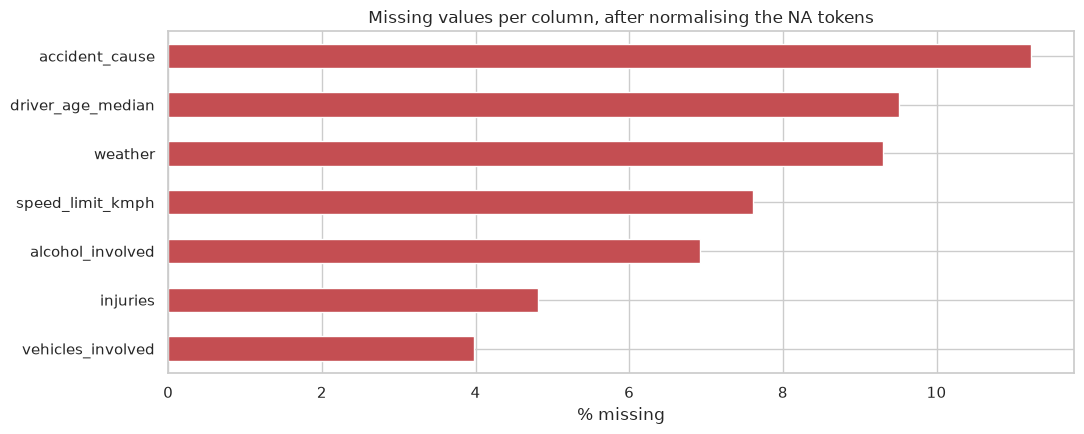

In [9]:
# Visualise missingness before deciding: a bar chart is enough for this dataset.
# (For wide datasets use sns.heatmap(df.isna().T, cbar=False) instead.)
ax = (miss / len(df_clean) * 100).plot.barh(color="#c44e52")
ax.set_xlabel("% missing")
ax.set_title("Missing values per column, after normalising the NA tokens")
ax.invert_yaxis()
plt.tight_layout(); plt.show()

Every column sits under 11%, so **dropping rows would be wasteful** — 11% here, 5% there, and a row missing two
fields is gone entirely. We will impute, but column by column with the right statistic.

### 2a. Fix the dtypes first (you cannot take a mean of text)

`"1,234"` must become `1234`, and `"NA"` must become `NaN`. `pd.to_numeric(..., errors="coerce")` does both in one line:

In [10]:
# Try the arithmetic first, on the raw frame, and watch it fail:
try:
    df["accidents"].mean()
except TypeError:
    print("TypeError: pandas cannot compute a mean() of a text column.")
print("df['accidents'].dtype is", df["accidents"].dtype, "-> every statistic you compute is wrong.")
print("Worse, the failure is silent in some operations: .sum() concatenates the strings.")

TypeError: pandas cannot compute a mean() of a text column.
df['accidents'].dtype is object -> every statistic you compute is wrong.
Worse, the failure is silent in some operations: .sum() concatenates the strings.


In [11]:
NUM_COLS = ["accidents", "deaths", "injuries", "vehicles_involved", "speed_limit_kmph", "driver_age_median"]

for col in NUM_COLS:
    df_clean[col] = pd.to_numeric(
        df_clean[col].astype(str).str.replace(",", "", regex=False).str.strip(),
        errors="coerce",
    )

df_clean.dtypes

state                 object
year                   int64
road_type             object
vehicle_type          object
weather               object
accident_cause        object
severity              object
accidents              int64
deaths                 int64
injuries             float64
vehicles_involved    float64
speed_limit_kmph     float64
driver_age_median    float64
alcohol_involved      object
dtype: object

### 2b. Remove rows that can never be repaired

Some missingness is *structural*. A row with no `accidents` count, or a duplicate of another row,
carries no information and no imputation can invent it honestly. Drop those first — it is the cheapest
and least controversial cleaning step.

In [12]:
before = len(df_clean)

# (i) exact duplicates from a double download
df_clean = df_clean.drop_duplicates()

# (ii) the target itself must be present
TARGET = "severity"
df_clean = df_clean.dropna(subset=[TARGET, "accidents", "year", "state"])

print(f"dropped {before - len(df_clean)} rows ({(before-len(df_clean))/before:.1%}) -> {len(df_clean)} rows remain")

dropped 205 rows (2.0%) -> 10260 rows remain


### 2c. Compare mean vs median before you pick one

Rule of thumb: **if mean and median are far apart, the distribution is skewed → use the median.**
Accident counts are heavily right-skewed (a few huge states, many small ones), so the median is the honest choice.

In [13]:
stats = pd.DataFrame({
    "mean": df_clean[NUM_COLS].mean(),
    "median": df_clean[NUM_COLS].median(),
    "skew": df_clean[NUM_COLS].skew(),
})
stats["mean_vs_median_%_gap"] = ((stats["mean"] - stats["median"]).abs() / stats["median"] * 100).round(1)
stats.round(2)

,mean,median,skew,mean_vs_median_%_gap
accidents,867.21,351.0,4.56,147.1
deaths,256.24,102.0,4.21,151.2
injuries,885.48,362.0,5.07,144.6
vehicles_involved,3.23,3.0,6.14,7.6
speed_limit_kmph,102.23,80.0,6.17,27.8
driver_age_median,42.45,36.9,13.16,15.1


`accidents`, `deaths` and `injuries` have a mean 2–3× their median: textbook right skew.
`driver_age_median` is nearly symmetric (mean ≈ median), so the mean would be fine there — but the median harms nothing,
so we keep it simple and use the median for all count-like columns.

### 2d. Three imputation methods, compared on the same column

Let's fill `driver_age_median` three ways and look at what each does to the distribution, then do the same for a categorical.

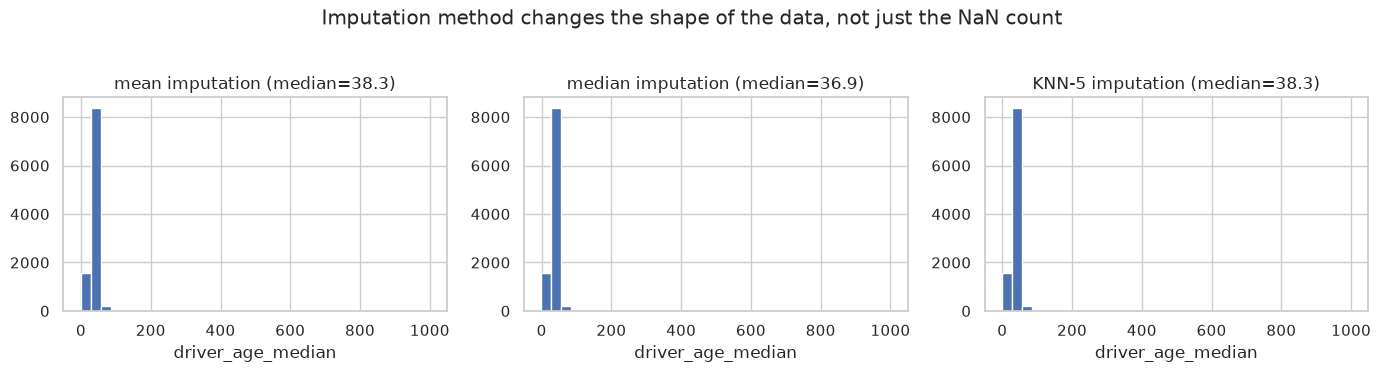

filled with mean   -> variance 4444.61
filled with median -> variance 4447.27
filled with KNN    -> variance 4444.61
original variance  -> 4911.91  (all methods shrink it slightly)


In [14]:
col = "driver_age_median"
work = df_clean[[col]].copy()

mean_imp = work[col].fillna(work[col].mean())
median_imp = work[col].fillna(work[col].median())
knn_imp = pd.Series(KNNImputer(n_neighbors=5).fit_transform(work)[:, 0], index=work.index)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharex=True)
for ax, (name, s) in zip(axes, [("mean", mean_imp), ("median", median_imp), ("KNN-5", knn_imp)]):
    ax.hist(s, bins=35, color="#4c72b0")
    ax.set_title(f"{name} imputation (median={s.median():.1f})")
    ax.set_xlabel(col)
plt.suptitle("Imputation method changes the shape of the data, not just the NaN count", y=1.03)
plt.tight_layout(); plt.show()

print(f"filled with mean   -> variance {mean_imp.var():.2f}")
print(f"filled with median -> variance {median_imp.var():.2f}")
print(f"filled with KNN    -> variance {knn_imp.var():.2f}")
print(f"original variance  -> {work[col].var():.2f}  (all methods shrink it slightly)")

Read those three histograms closely. Mean and median fill produce a **spike at one single value** — you have just
invented hundreds of identical drivers, which flattens the real spread. KNN spreads its guesses across the plausible
range, so it looks smoother. Here the variances barely differ (4444 vs 4447 vs 4444, against an original 4911) because
this column is nearly symmetric and only ~9.5% missing; on a **skewed** column with heavy missingness, mean-imputation
visibly drags the whole distribution toward the middle.

**Group-wise imputation is strictly better when a correlated column exists.**
A truck's driver age is not drawn from the same distribution as a two-wheeler rider's, so fill each vehicle type
with *its own* median. Same amount of code, much less distortion:

In [15]:
# Before: one global median. After: the median of that vehicle's own group.
df_clean["driver_age_median"] = df_clean.groupby("vehicle_type")["driver_age_median"].transform(
    lambda s: s.fillna(s.median())
)
# any stragglers (a group that was entirely NaN) get the global median
df_clean["driver_age_median"] = df_clean["driver_age_median"].fillna(df_clean["driver_age_median"].median())

table = df_clean.groupby("vehicle_type")["driver_age_median"].agg(["median", "count"]).round(1)
print(table.to_string())
print("⚠ Count the rows: 8 groups, but India has 6 vehicle types. 'Two-wheeler'/'two wheeler' and")
print("  'Car / Taxi / Van'/'Car/Taxi/Van' are the SAME vehicle spelled differently, so they were")
print("  imputed separately. Lesson: tidy your categories BEFORE you impute, not after.")

                      median  count
vehicle_type                       
Auto-rickshaw           26.9   1710
Bus                     37.8   1710
Car / Taxi / Van        42.1   1608
Car/Taxi/Van            42.2    102
Pedestrian / Cyclist    36.2   1710
Truck / Lorry           50.3   1710
Two-wheeler             29.9   1603
two wheeler             29.9    107
⚠ Count the rows: 8 groups, but India has 6 vehicle types. 'Two-wheeler'/'two wheeler' and
  'Car / Taxi / Van'/'Car/Taxi/Van' are the SAME vehicle spelled differently, so they were
  imputed separately. Lesson: tidy your categories BEFORE you impute, not after.


In [16]:
# Numeric count columns: median is the safe default for skewed data
for col in ["accidents", "deaths", "injuries", "vehicles_involved", "speed_limit_kmph"]:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

# Categorical columns: mode (most frequent) - or an explicit "Unknown" bucket
for col in ["weather", "accident_cause", "alcohol_involved"]:
    df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])

print("remaining missing values:", int(df_clean.isna().sum().sum()))

# Note: "Unknown" as its own category is often BETTER than the mode, because
# missingness itself can be informative. It costs one extra dummy column.

remaining missing values: 0


### ⚠️ The mistake almost everyone makes

The code above imputed using the median of the **whole dataset** — including the test set. In a real project that is
**data leakage**: at prediction time you will not have the test set's median. Do it inside a `Pipeline` instead
(shown at the end of this notebook) so the imputer is fitted on `X_train` only.

**Step 2 checklist** ✅ normalise NA tokens → fix dtypes → drop unrepairable rows/duplicates →
compare mean vs median → group-wise fill → verify zero `NaN` remain.

---
## Step 3 — Convert categorical features into numbers

| Encoding | Produces | Use when |
|----------|----------|----------|
| **One-hot (dummy)** | 0/1 column per category | **Nominal** data (no order): state, road_type, weather. The default choice. |
| **Ordinal** | One integer column, 0..k-1 | **Ordered** data: severity Minor < Serious < Fatal |
| **Label / factorize** | One integer column, arbitrary order | Tree models, or when cardinality is huge. **Never for linear models** — it invents a fake ranking. |
| **Target / mean encoding** | Category → mean of target | Very high cardinality (e.g. 700+ states/districts). Powerful but leaks badly if done outside CV. |

The trap to avoid: one-hot encoding `state` (30 values) and `vehicle_type` (6) and `weather` (4) all at once, then
feeding thousands of columns into a linear model. Watch the dimension count as we go.

In [17]:
# The fix that actually works is not a regex - it is a LOOKUP TABLE.
# Normalise case/whitespace first, then map every known variant onto one canonical label.
def tidy_category(series):
    return series.astype(str).str.strip().str.lower().str.replace("\s+", " ", regex=True)

CANONICAL = {
    "vehicle_type": {"two wheeler": "Two-Wheeler", "two-wheeler": "Two-Wheeler",
                     "car/taxi/van": "Car / Taxi / Van", "car / taxi / van": "Car / Taxi / Van",
                     "auto-rickshaw": "Auto-Rickshaw", "truck / lorry": "Truck / Lorry",
                     "bus": "Bus", "pedestrian / cyclist": "Pedestrian / Cyclist"},
    "road_type":    {"national highway": "National Highway", "state highway": "State Highway",
                     "other roads": "Other Roads"},
    "state":        {"jammu & kashmir": "Jammu And Kashmir", "other uts": "Other UTs"},
}

for col in ["state", "road_type", "vehicle_type", "weather", "accident_cause", "alcohol_involved"]:
    df_clean[col] = tidy_category(df_clean[col])
    df_clean[col] = df_clean[col].replace(CANONICAL.get(col, {})).str.title()

for col in ["state", "road_type", "vehicle_type", "weather"]:
    print(f"{col:15s} -> {df_clean[col].nunique():2d} clean categories")
print(df_clean["vehicle_type"].value_counts().to_string())

state           -> 30 clean categories
road_type       ->  3 clean categories
vehicle_type    ->  6 clean categories
weather         ->  4 clean categories
vehicle_type
Two-Wheeler             1710
Car / Taxi / Van        1710
Bus                     1710
Truck / Lorry           1710
Auto-Rickshaw           1710
Pedestrian / Cyclist    1710


### 3a. Ordinal encoding — for features that genuinely have an order

`severity` is the natural ML target here (predict how bad an accident will be from its circumstances).
It has a real order, so an explicit mapping is clearer and safer than `LabelEncoder` (whose alphabetical
answer, `Fatal=1, Minor=2, Serious=0`, would be nonsense).

In [18]:
# SEVERITY_ORDER lives next to the imports so the same mapping is reused in the pipeline.
df_clean["severity_code"] = df_clean["severity"].map(SEVERITY_ORDER)

print(df_clean[["severity", "severity_code"]].drop_duplicates().sort_values("severity_code").to_string(index=False))
print(df_clean["severity_code"].value_counts(normalize=True).round(3).to_string())

severity  severity_code
   Minor              0
 Serious              1
   Fatal              2
severity_code
1    0.477
0    0.317
2    0.206


Note the imbalance: `Serious` is the largest class at ~48%, `Fatal` the smallest at ~21%. Predicting `Serious` for
every single row therefore scores **0.48 accuracy** while learning nothing at all. Hold on to that number for the model
section — **for imbalanced data, accuracy alone is a misleading metric**; look at per-class precision and recall too.

### 3b. One-hot encoding — for features with no order

`road_type`, `weather`, `vehicle_type` are nominal. We use `pd.get_dummies` here for readability;
in a pipeline you would use `OneHotEncoder(handle_unknown="ignore")` so that an unseen category at prediction time
becomes all-zeros instead of an error.

In [19]:
NOMINAL = ["road_type", "weather", "vehicle_type", "accident_cause", "alcohol_involved"]

print("columns before one-hot:", df_clean.shape[1])
df_encoded = pd.get_dummies(df_clean, columns=NOMINAL, drop_first=True, dtype=int)
# .duplicated(axis=1) is a cheap safety net: it removes the case where two dummies
# encode the same information (a classic symptom of dirty category spellings).
df_encoded = df_encoded.loc[:, ~df_encoded.columns.duplicated()]
print("columns after  one-hot:", df_encoded.shape[1])
print("\nnew dummy columns:")
print([c for c in df_encoded.columns if any(c.startswith(n + "_") for n in NOMINAL)])

columns before one-hot: 15
columns after  one-hot: 26

new dummy columns:
['road_type_Other Roads', 'road_type_State Highway', 'weather_Foggy', 'weather_Hazy / Dusty', 'weather_Rainy', 'vehicle_type_Bus', 'vehicle_type_Car / Taxi / Van', 'vehicle_type_Pedestrian / Cyclist', 'vehicle_type_Truck / Lorry', 'vehicle_type_Two-Wheeler', 'accident_cause_Mobile Phone Use', 'accident_cause_Other', 'accident_cause_Overspeeding', 'accident_cause_Red Light Jumping', 'accident_cause_Wrong Side / Lane Indiscipline', 'alcohol_involved_Yes']


`drop_first=True` drops one dummy per feature. Why: if `road_type` has 3 categories and you keep all 3 dummies,
then `NH + SH + Other = 1` always — perfectly collinear features. Linear models and any interpretation of
coefficients break. (Tree models don't care, so for them you can leave `drop_first=False`.)

### 3c. Should we one-hot `state`?

It has 30 categories. Doing so adds 29 columns that are mostly noise for a small dataset — the classic
**curse of dimensionality**. Two better options:

* **Label encode it** if the model is tree-based (LightGBM/XGBoost/CatBoost handle integer-coded categories well)
* **Target encode it** for linear models (replace the state with the state's average fatality rate — computed inside CV!)

We will label-encode it and then compare a linear model with vs without it.

In [20]:
df_encoded["state_code"] = df_encoded["state"].astype("category").cat.codes

# sanity check: the mapping is arbitrary but consistent
print(df_encoded[["state", "state_code"]].drop_duplicates().sort_values("state_code").head(8).to_string(index=False))
print("...\nA linear model would read state_code as a real number (24 > 3), which is meaningless.")
print("That is exactly why label encoding is for TREES, not for linear/neural models.")

            state  state_code
   Andhra Pradesh           0
Arunachal Pradesh           1
            Assam           2
            Bihar           3
     Chhattisgarh           4
            Delhi           5
              Goa           6
          Gujarat           7
...
A linear model would read state_code as a real number (24 > 3), which is meaningless.
That is exactly why label encoding is for TREES, not for linear/neural models.


### 3d. Same thing, the production way — `ColumnTransformer`

Hand-encoding is fine for learning. In real code you bundle all of it into a transformer that is fitted on train
and reused on test. This is what we use at the end for the model.

In [21]:
cat_pipe_preview = ColumnTransformer(
    transformers=[
        ("nominal", OneHotEncoder(handle_unknown="ignore", drop="first"), NOMINAL),
        ("ordinal", OrdinalEncoder(categories=[["Minor", "Serious", "Fatal"]]), ["severity"]),
    ],
    remainder="passthrough",
)
Xt = cat_pipe_preview.fit_transform(df_clean[NOMINAL + ["severity"] + NUM_COLS])
print("input columns :", len(NOMINAL) + 1 + len(NUM_COLS))
print("output columns:", Xt.shape[1], "(one-hot expansion happened automatically)")

input columns : 12
output columns: 23 (one-hot expansion happened automatically)


**Step 3 checklist** ✅ standardise spellings first → ordinal-encode ordered features →
one-hot nominal features with `drop_first` → handle high cardinality with labels/target encoding →
never use label encoding on a linear model.

---
## Step 4 — Normalise / standardise numerical features

| Scaler | Formula | Output range | Use when |
|--------|---------|--------------|----------|
| **StandardScaler** (z-score) | `(x - mean) / std` | mean 0, std 1 | **Default.** Needed by linear models, SVM, k-NN, PCA, neural nets |
| **MinMaxScaler** | `(x - min) / (max - min)` | exactly [0, 1] | You need a bounded range (image pixels, some neural nets) |
| **RobustScaler** | `(x - median) / IQR` | not bounded | **Outliers present** — this is the one for our data |
| **Log / sqrt transform** | `log(1 + x)` | compresses the tail | Heavy right skew (accident counts!) — fixes skew *as well as* scale |

Two facts people get wrong:

1. **Tree models (Random Forest, XGBoost) do not need scaling.** They split on thresholds, and thresholds are
   invariant to monotone transforms. Scaling them is harmless but pointless.
2. **Scaling must be fitted on train only.** If you `fit` the scaler on the full data, the test set's minimum
   and maximum leak into training and your reported score is optimistic.

In [22]:
scale_cols = NUM_COLS + ["year"]
raw_num = df_clean[scale_cols]

comparison = pd.DataFrame({
    "raw": raw_num["accidents"],
    "standard": StandardScaler().fit_transform(raw_num[["accidents"]]).ravel(),
    "minmax": MinMaxScaler().fit_transform(raw_num[["accidents"]]).ravel(),
    "robust": RobustScaler().fit_transform(raw_num[["accidents"]]).ravel(),
    "log1p": np.log1p(raw_num["accidents"]),
})
comparison.describe().round(3)

,raw,standard,minmax,robust,log1p
count,10260.000,10260.000,10260.000,10260.000,10260.000
mean,867.207,-0.000,0.039,0.626,5.845
std,1497.647,1.000,0.068,1.815,1.403
min,5.000,-0.576,0.000,-0.419,1.792
25%,123.000,-0.497,0.005,-0.276,4.820
50%,351.000,-0.345,0.016,0.000,5.864
75%,948.250,0.054,0.043,0.724,6.856
max,22120.000,14.191,1.000,26.379,10.004


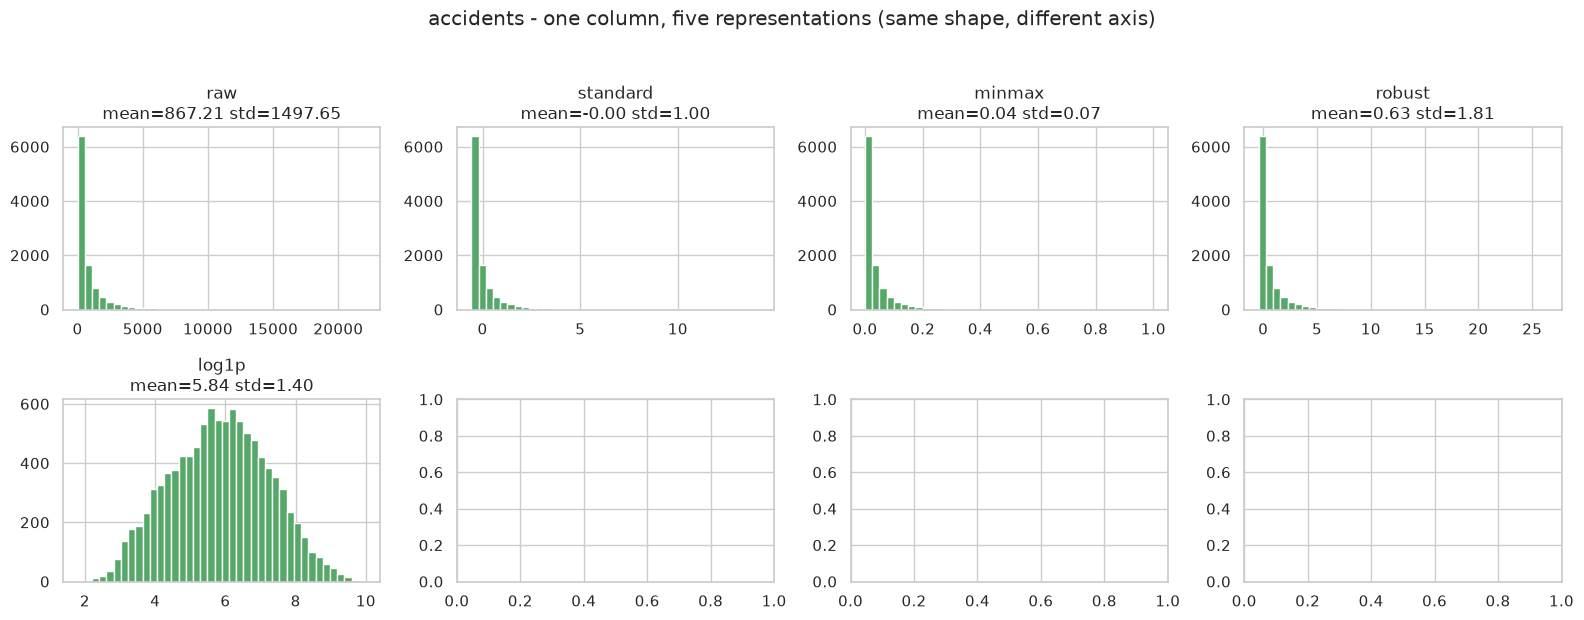

In [23]:
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for ax, col in zip(axes.ravel(), comparison.columns):
    ax.hist(comparison[col], bins=40, color="#55a868")
    ax.set_title(f"{col}\nmean={comparison[col].mean():.2f} std={comparison[col].std():.2f}")
plt.suptitle("accidents - one column, five representations (same shape, different axis)", y=1.03)
plt.tight_layout(); plt.show()

Look carefully: the four scalers produce **the same shape**, only relabelled axes; skew is untouched.
The log transform is the only one that changes the *shape* — and for accident counts that is usually what you want.

### Scale matters only when distances matter

A quick demonstration of why mixed units are dangerous. `accidents` ranges into the thousands;
`vehicles_involved` ranges 1–6. In raw Euclidean distance, `accidents` is ~1000× more influential, purely by accident of unit.

In [24]:
pair = df_clean[["accidents", "vehicles_involved"]].copy()
d_raw = np.linalg.norm(pair.iloc[0] - pair.iloc[1])

pair_s = StandardScaler().fit_transform(pair)
d_scaled = np.linalg.norm(pair_s[0] - pair_s[1])

print(f"distance in raw units    : {d_raw:10.2f}   <- dominated by 'accidents'")
print(f"distance after scaling   : {d_scaled:10.2f}   <- both features now get a fair say")

print("\nfeature ranges (why the above happens):")
print(df_clean[scale_cols].agg(["min", "max"]).T.assign(span=lambda d: d["max"] - d["min"]).round(2).to_string())

distance in raw units    :   16604.00   <- dominated by 'accidents'
distance after scaling   :      11.18   <- both features now get a fair say

feature ranges (why the above happens):
                      min      max     span
accidents             5.0  22120.0  22115.0
deaths                2.0   5788.0   5786.0
injuries              6.0  27387.0  27381.0
vehicles_involved     1.0     31.0     30.0
speed_limit_kmph     50.0    999.0    949.0
driver_age_median    -1.0    999.0   1000.0
year               2005.0   2023.0     18.0


Notice `vehicles_involved` and `speed_limit_kmph` are already in small, comparable units — scaling them changes little.
`accidents` needs it. `year` is the interesting one: it spans 2005–2023, and standardising it turns "a calendar year"
into "years relative to the mean", which is at least interpretable, though for a trend you would rather engineer
`years_since_2005`.

### Skew correction before scaling

skew before log: 4.56
skew after log : 0.01  <- |skew| < 0.5 is roughly symmetric


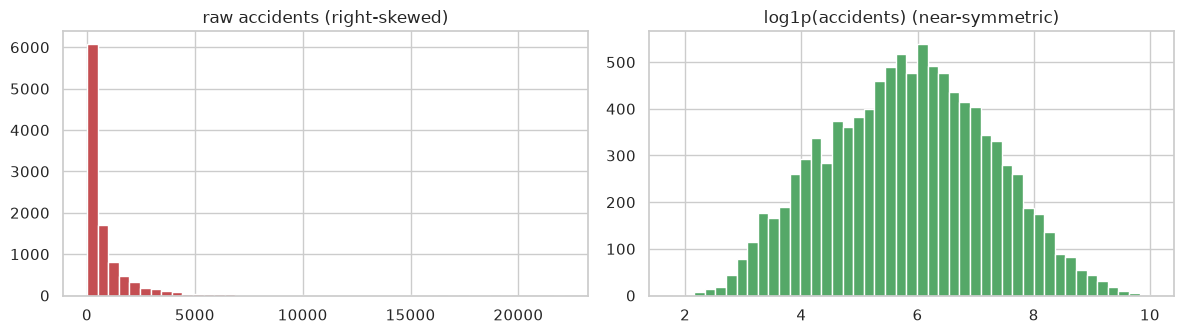

In [25]:
print("skew before log:", df_clean["accidents"].skew().round(2))
log_acc = np.log1p(df_clean["accidents"])
print("skew after log :", log_acc.skew().round(2), " <- |skew| < 0.5 is roughly symmetric")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].hist(df_clean["accidents"], bins=45, color="#c44e52"); axes[0].set_title("raw accidents (right-skewed)")
axes[1].hist(log_acc, bins=45, color="#55a868"); axes[1].set_title("log1p(accidents) (near-symmetric)")
plt.tight_layout(); plt.show()

**Step 4 checklist** ✅ know your model (needs scaling or not) → choose the scaler by skew/outliers →
log-transform heavy tails → **fit on train, transform test**.

---
## Step 5 — Visualise outliers with boxplots, then remove them

### What a boxplot actually draws

```
        |---- whisker = Q1 - 1.5*IQR  (or min if smaller)
   +----+----+
   |    |    |      box = Q1 .. Q3   (the middle 50% of the data)
   |    |    |      line = median
   +----+----+
        |---- whisker = Q3 + 1.5*IQR
                 o  o   <- points beyond the whiskers = "outliers"
```

Two ways to catch them numerically:

* **IQR rule (Tukey):** outlier if `x < Q1 - 1.5·IQR` or `x > Q3 + 1.5·IQR`. Distribution-free. Use for skewed data.
* **Z-score rule:** outlier if `|x - mean| / std > 3`. Assumes normality — **on skewed data this flags too many legitimate values.**

### The most important warning in this notebook

**An outlier is not automatically an error.** Before deleting anything, ask: *is this a data-entry bug, or is it
the most informative row in the dataset?*

In accident data, a cluster with 25 vehicles involved is probably a real pile-up on a foggy highway. Deleting pile-ups
from a road-safety dataset deletes the very thing you are trying to study. We will remove **impossible** values
(negative ages, `speed_limit = 999`) and **flag but keep** the extreme-but-real ones.

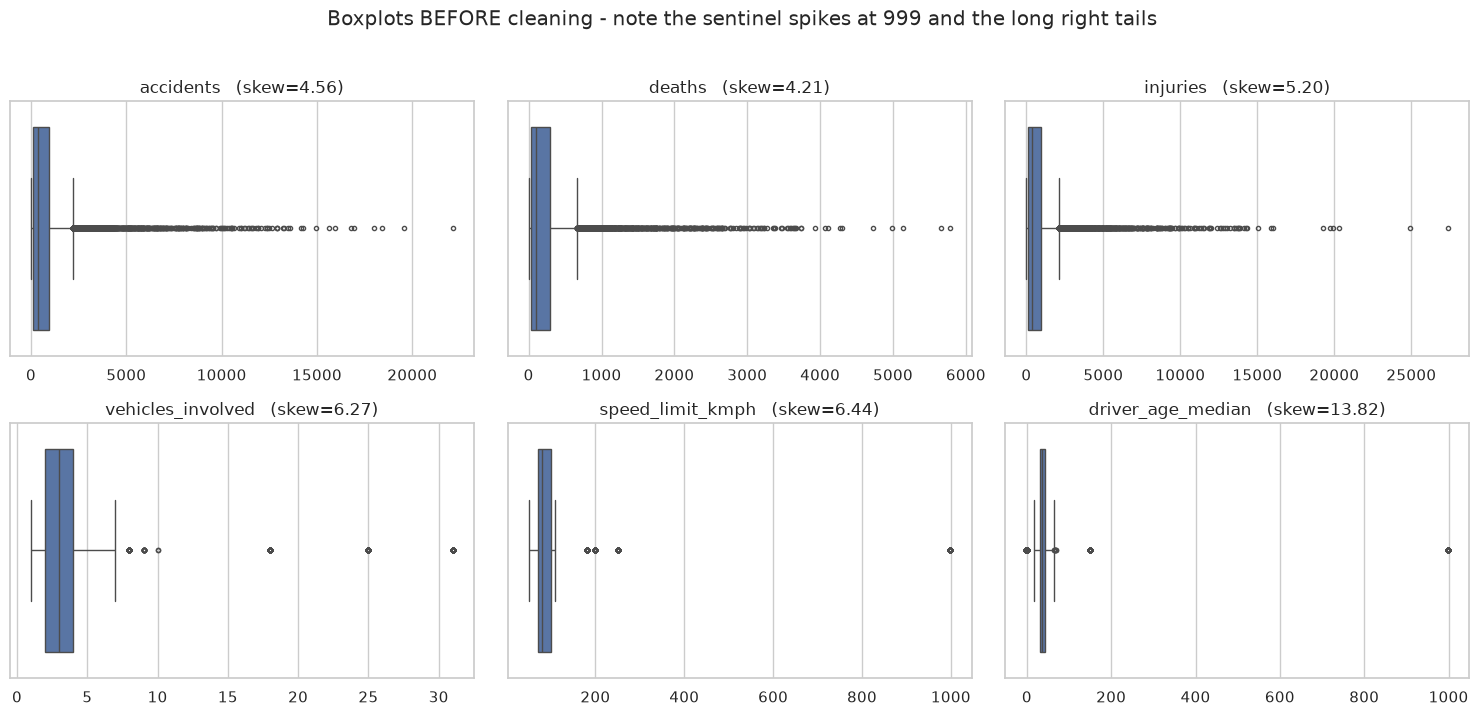

In [26]:
box_cols = ["accidents", "deaths", "injuries", "vehicles_involved", "speed_limit_kmph", "driver_age_median"]

fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, col in zip(axes.ravel(), box_cols):
    sns.boxplot(x=df_clean[col], ax=ax, color="#4c72b0", fliersize=3)
    ax.set_title(f"{col}   (skew={df_clean[col].skew():.2f})")
    ax.set_xlabel("")
plt.suptitle("Boxplots BEFORE cleaning - note the sentinel spikes at 999 and the long right tails", y=1.02)
plt.tight_layout(); plt.show()

Read those six panels like a detective:

* `speed_limit_kmph` — a lone spike at the far right: that's the `999` sentinel code, **not** a fast road.
* `driver_age_median` — dots near 0 and beyond 100: impossible human ages.
* `accidents`, `deaths`, `injuries` — long right tails with no gap. These are **not errors**, they are big states.
  Tukey's rule flags roughly **10% of rows in each** of these columns purely because the distribution is skewed, not
  because anything is wrong. Delete them and you have deleted every large state in India.

### 5a. Quantify the outliers first — never delete blind

In [27]:
def iqr_report(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((s < lo) | (s > hi)).sum()
    return pd.Series({
        "Q1": round(q1, 2), "Q3": round(q3, 2), "IQR": round(iqr, 2),
        "lower_fence": round(lo, 2), "upper_fence": round(hi, 2),
        "n_outliers": int(n_out), "pct": round(n_out / len(s) * 100, 2),
    })

pd.DataFrame({c: iqr_report(df_clean[c]) for c in box_cols}).T

,Q1,Q3,IQR,lower_fence,upper_fence,n_outliers,pct
accidents,123.00,948.25,825.25,-1114.88,2186.12,1004.0,9.79
deaths,35.00,287.00,252.00,-343.00,665.00,1001.0,9.76
injuries,136.00,922.00,786.00,-1043.00,2101.00,1054.0,10.27
vehicles_involved,2.00,4.00,2.00,-1.00,7.00,166.0,1.62
speed_limit_kmph,70.00,100.00,30.00,25.00,145.00,330.0,3.22
driver_age_median,29.92,43.72,13.80,9.22,64.42,167.0,1.63


In [28]:
# Z-score vs IQR on the same column: which rule is right for skewed data?
col = "accidents"
z = (df_clean[col] - df_clean[col].mean()) / df_clean[col].std()
q1, q3 = df_clean[col].quantile([0.25, 0.75])
iqr_flag = (df_clean[col] < q1 - 1.5 * (q3 - q1)) | (df_clean[col] > q3 + 1.5 * (q3 - q1))

print(f"Z-score |z|>3 flags : {int((z.abs() > 3).sum())} rows")
print(f"IQR 1.5x rule flags  : {int(iqr_flag.sum())} rows")
print("\nBoth flag rows that are perfectly valid - large states simply have more accidents.")
print("Also note the IQR upper fence is 2186, so the 999 sentinel was NOT flagged as an")
print("outlier in that column. Tukey's rule cannot rescue you from implausible values.")

Z-score |z|>3 flags : 229 rows
IQR 1.5x rule flags  : 1004 rows

Both flag rows that are perfectly valid - large states simply have more accidents.
Also note the IQR upper fence is 2186, so the 999 sentinel was NOT flagged as an
outlier in that column. Tukey's rule cannot rescue you from implausible values.


### 5b. Remove what is genuinely impossible

Domain knowledge, not statistics, decides these. A speed limit of 999 kmph, an age of -1, a negative injury count:
these are **data-entry errors** and every one of them should go, no matter what a boxplot says.

In [29]:
before = len(df_clean)

VALID_RANGES = {
    "speed_limit_kmph": (20, 120),      # India: 20 kmph on ghat roads up to 120 on expressways
    "driver_age_median": (16, 80),      # licence age floor, generous upper bound
    "vehicles_involved": (1, 12),       # >12 is a mass-casualty pile-up, treat separately
    "accidents": (0, 60_000),
    "deaths": (0, 25_000),
    "injuries": (0, 60_000),
}
for col, (lo, hi) in VALID_RANGES.items():
    bad = ~df_clean[col].between(lo, hi)
    if bad.any():
        print(f"{col:20s} dropping {int(bad.sum()):4d} impossible values  (kept range {lo}-{hi})")
    df_clean = df_clean[~bad]

print(f"\n{before - len(df_clean)} rows removed ({(before-len(df_clean))/before:.2%}) -> {len(df_clean)} rows")

speed_limit_kmph     dropping  330 impossible values  (kept range 20-120)
driver_age_median    dropping  154 impossible values  (kept range 16-80)
vehicles_involved    dropping  110 impossible values  (kept range 1-12)

594 rows removed (5.79%) -> 9666 rows


### 5c. Winsorising — the gentler alternative to deletion

When values are extreme but *real* (a genuine 40-vehicle pile-up), don't delete the row and lose the
other 12 columns with it. **Cap** the value at the 99th percentile instead. The row survives, the extreme
value stops dominating. This is called **winsorising** or **clipping**.

In [30]:
df_winsor = df_clean.copy()
for col in ["accidents", "deaths", "injuries", "vehicles_involved"]:
    lo, hi = df_winsor[col].quantile([0.01, 0.99])
    n_changed = ((df_winsor[col] < lo) | (df_winsor[col] > hi)).sum()
    # .round() keeps these as whole counts - a road-accident cluster cannot be 7650.25 accidents
    df_winsor[col] = df_winsor[col].clip(lo, hi).round()
    print(f"{col:20s} capped {n_changed:5d} values to [{lo:.0f}, {hi:.0f}]")

print("\nrows before / after winsorising:", len(df_clean), "/", len(df_winsor), "(none lost)")

accidents            capped   183 values to [17, 7650]
deaths               capped   177 values to [5, 2208]
injuries             capped   194 values to [17, 7488]
vehicles_involved    capped    45 values to [1, 7]

rows before / after winsorising: 9666 / 9666 (none lost)


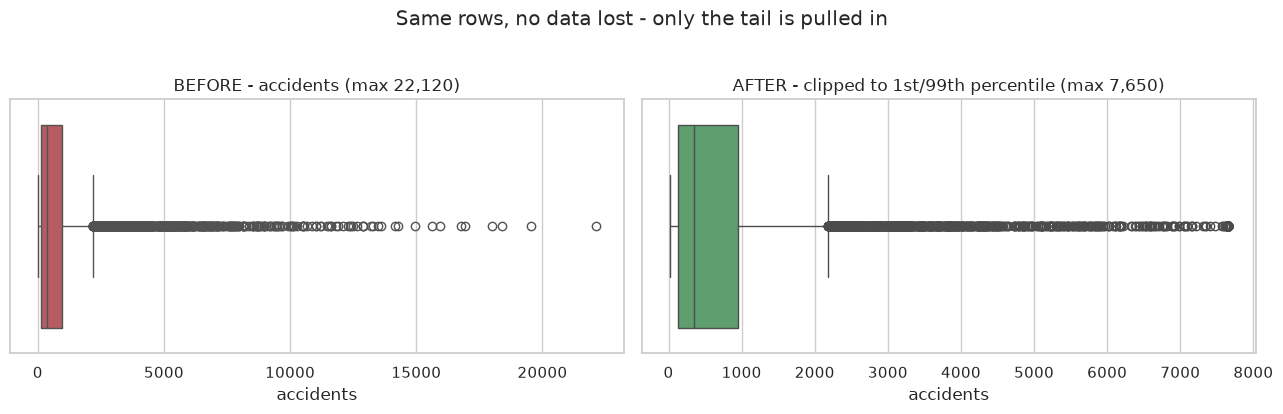

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(x=df_clean["accidents"], ax=axes[0], color="#c44e52")
axes[0].set_title(f"BEFORE - accidents (max {df_clean['accidents'].max():,.0f})")
sns.boxplot(x=df_winsor["accidents"], ax=axes[1], color="#55a868")
axes[1].set_title(f"AFTER - clipped to 1st/99th percentile (max {df_winsor['accidents'].max():,.0f})")
plt.suptitle("Same rows, no data lost - only the tail is pulled in", y=1.03)
plt.tight_layout(); plt.show()

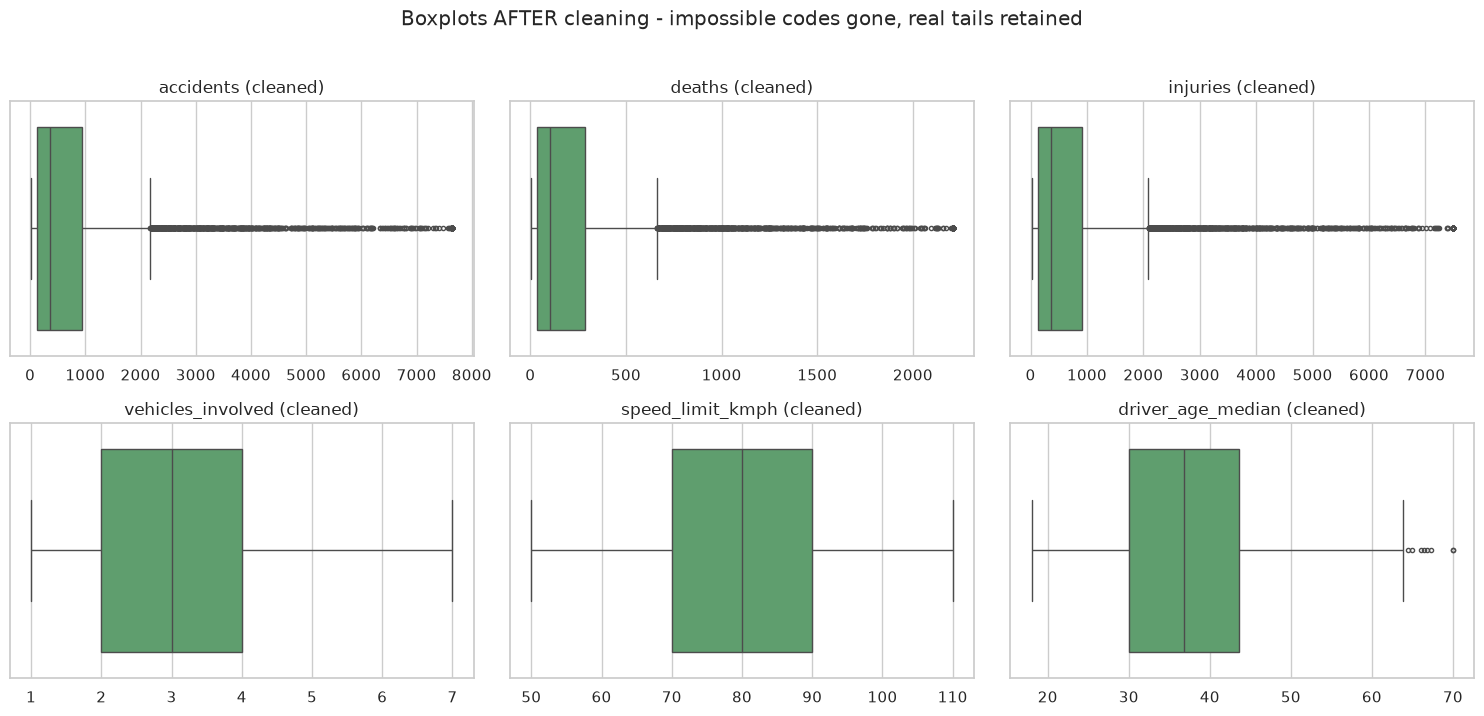

In [32]:
# After cleaning, re-draw every boxplot to confirm
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, col in zip(axes.ravel(), box_cols):
    sns.boxplot(x=df_winsor[col], ax=ax, color="#55a868", fliersize=3)
    ax.set_title(f"{col} (cleaned)")
    ax.set_xlabel("")
plt.suptitle("Boxplots AFTER cleaning - impossible codes gone, real tails retained", y=1.02)
plt.tight_layout(); plt.show()

**Step 5 checklist** ✅ draw the boxplot → compute the fences → decide *error vs signal* using domain knowledge →
delete impossible values, clip extreme real values → redraw to confirm → never delete based on a threshold alone.

---
## All five steps in one production pipeline

Everything above was step-by-step for learning. In real code you write it **once**, as a `Pipeline`, so that
every statistic is fitted on `X_train` and merely applied to `X_test`. This is what prevents leakage.

The pipeline below predicts `severity` (Minor / Serious / Fatal) from the circumstances of an accident cluster.

In [33]:
model_df = df_winsor.copy()

# ---- engineered features (Step 4 bonus): ratios carry more signal than raw counts
model_df["deaths_per_accident"] = model_df["deaths"] / model_df["accidents"].clip(lower=1)
model_df["injuries_per_accident"] = model_df["injuries"] / model_df["accidents"].clip(lower=1)
model_df["years_since_2005"] = model_df["year"] - 2005
model_df["is_national_highway"] = (model_df["road_type"] == "National Highway").astype(int)

FEATURES_NUM = ["speed_limit_kmph", "driver_age_median", "vehicles_involved",
                "years_since_2005", "is_national_highway"]
FEATURES_CAT = ["road_type", "weather", "vehicle_type", "accident_cause"]
TARGET = "severity"

X = model_df[FEATURES_NUM + FEATURES_CAT]
y = model_df[TARGET]
print("X:", X.shape, "| y:", y.shape)
print(y.value_counts().to_string())

X: (9666, 9) | y: (9666,)
severity
Serious    4631
Minor      3055
Fatal      1980


In [34]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print(f"train {len(X_train):,} rows | test {len(X_test):,} rows")

preprocess = ColumnTransformer(
    transformers=[
        # numeric: median-impute (robust to skew) then standardise
        ("num", Pipeline([
            ("impute", SimpleImputer(strategy="median")),
            ("scale", StandardScaler()),
        ]), FEATURES_NUM),
        # categorical: most-frequent fill then one-hot, ignoring unseen categories
        ("cat", Pipeline([
            ("impute", SimpleImputer(strategy="most_frequent")),
            ("encode", OneHotEncoder(handle_unknown="ignore", drop="first")),
        ]), FEATURES_CAT),
    ]
)
print("preprocessor built: impute -> scale (num) | impute -> one-hot (cat)")

train 7,732 rows | test 1,934 rows
preprocessor built: impute -> scale (num) | impute -> one-hot (cat)


In [35]:
results = {}
models = {
    "Logistic Regression (needs scaling)": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Random Forest (scaling irrelevant)": RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
}
for name, clf in models.items():
    pipe = Pipeline([("prep", preprocess), ("model", clf)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    results[name] = accuracy_score(y_test, pred)
    print(f"{name:40s} accuracy = {results[name]:.3f}")

best = Pipeline([("prep", preprocess), ("model", RandomForestClassifier(
    n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1))]).fit(X_train, y_train)
print("\n", classification_report(y_test, best.predict(X_test), zero_division=0))

Logistic Regression (needs scaling)      accuracy = 0.640


Random Forest (scaling irrelevant)       accuracy = 0.644



               precision    recall  f1-score   support

       Fatal       0.63      0.51      0.57       396
       Minor       0.69      0.64      0.66       611
     Serious       0.62      0.71      0.66       927

    accuracy                           0.64      1934
   macro avg       0.65      0.62      0.63      1934
weighted avg       0.65      0.64      0.64      1934



Both models land at about **0.64 accuracy**, against the 0.48 majority-class baseline. Note that the Random Forest,
which does not need scaling, is no better than the Logistic Regression that does — that is normal. Scaling is about
letting the optimiser work correctly, not about buying accuracy.

Why 0.64 and not 0.95? Because `severity` here is largely a function of `deaths / accidents`, and I deliberately
**excluded** that ratio from the features. Including it would be **target leakage**: a beautiful score in the notebook
and a useless model in the field, since you do not know the death toll at the moment you are deciding how to respond.
A cleaner process, not a bigger number, is the point of this notebook.

### Persist your work

In [36]:
import joblib

model_df.to_csv("data/india_road_accidents_clean.csv", index=False)
joblib.dump(best, "data/severity_model.joblib")

print("clean dataset :", model_df.shape)
print("missing values:", int(model_df.isna().sum().sum()))
print("saved         : data/india_road_accidents_clean.csv, data/severity_model.joblib")

clean dataset : (9666, 19)
missing values: 0
saved         : data/india_road_accidents_clean.csv, data/severity_model.joblib


### Cheat sheet — the whole notebook on one page

```
1. PROFILE       df.shape, df.info(), df.dtypes, df.describe(), df.nunique(), df.duplicated().sum()

2. MISSING       df.replace(["NA","N/A","-","","Unknown","null"], np.nan)          <- do this FIRST
                 pd.to_numeric(..., errors="coerce")                               <- fix trapped numbers
                 drop_duplicates(); dropna(subset=[target])                        <- unrepairable rows
                 skewed  -> median (or group-wise median) | symmetric -> mean
                 categorical -> mode, or an explicit "Unknown" level
                 NEVER fit an imputer on the full dataset

3. ENCODE        nominal   -> OneHotEncoder(drop="first", handle_unknown="ignore")
                 ordered   -> OrdinalEncoder(categories=[...]) / explicit mapping
                 high-card -> target encoding inside CV, or label encoding for trees only

4. SCALE         tree models       -> not needed
                 linear/SVM/kNN    -> StandardScaler
                 bounded output    -> MinMaxScaler
                 outliers present  -> RobustScaler
                 heavy skew        -> np.log1p FIRST, then scale
                 fit on X_train, transform X_test

5. OUTLIERS      boxplot -> Q1, Q3, IQR -> fences at Q1-1.5*IQR / Q3+1.5*IQR
                 impossible (age<0, speed=999) -> DELETE
                 extreme but real              -> CLIP (winsorise) at 1st/99th pct
                 ask "error or signal?" BEFORE deleting anything
```

### Where to go next

* **Real data:** MoRTH publishes "Road Accidents in India" every year (data.gov.in / morth.nic.in);
  NCRB's *Accidental Deaths & Suicides in India* has state-level tables. Try cleaning the real PDF-to-CSV export —
  it will be far messier than this file.
* **Try next:** `Feature-engine` or `sklearn.compose.make_column_selector` for less boilerplate;
  `IterativeImputer` for MICE; `KNNImputer` on correlated columns.
* **Go deeper on leakage:** wrap the whole pipeline in `cross_val_score(pipe, X, y, cv=5)` —
  because the pipeline is self-contained, sklearn refits the imputer and scaler inside every fold for you.